# Quanto vale um cliente novo nos próximos meses, e quando dá para considerar que ele foi embora?

É a conta que define o teto do custo de aquisição (quanto dá para pagar por um cliente) e o momento de gastar com
reativação. A base é a **Online Retail II** (UCI, CC BY 4.0): dois anos de vendas de um varejista online britânico,
boa parte para revendedores.

O desenho é o de quem usaria o resultado: **um ano para aprender** (1/12/2009 a 30/11/2010) e **o ano seguinte para
conferir** (1/12/2010 a 30/11/2011). Nada do segundo ano entra no ajuste.

Os modelos (BG/NBD, Gamma-Gamma, Kaplan-Meier) estão implementados em `src/valor_cliente/`, em NumPy/SciPy, e
conferidos em `tests/` contra integrais numéricas, dados simulados e exemplos publicados.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from valor_cliente import analise, dados, graficos
from valor_cliente import avaliacao as av

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_columns", 30)


def mostrar(figura):
    display(figura)
    plt.close(figura)

## 1. Os dados e a limpeza

O bruto tem uma linha por item de fatura. `scripts/baixar_dados.py` baixa, limpa e grava o extrato usado aqui: uma
linha por cliente e dia com compra. Cada passo da limpeza está contado abaixo.

In [2]:
compras, cancelamentos, limpeza = dados.carregar_compras(), dados.carregar_cancelamentos(), dados.carregar_limpeza()
pd.Series({k: v for k, v in limpeza.items() if k not in ("fonte", "sha256_do_zip")}, name="valor").to_frame()

,valor
linhas_brutas,1067371
linhas_repetidas_entre_abas,22523
linhas_sem_cliente,235287
linhas_de_cancelamento,18446
valor_dos_cancelamentos,"1,087,882.140"
valor_dos_cancelamentos_de_itens_nao_produto,"374,872.490"
linhas_de_outras_faturas_nao_venda,0
linhas_com_quantidade_ou_preco_nao_positivo,70
linhas_de_itens_nao_produto,2858
valor_dos_itens_nao_produto,"306,624.950"


Três decisões que mudam o resultado:

- **Uma compra = um dia com compra.** Várias faturas no mesmo dia contam como uma ocasião.
- **Cancelamentos.** Tirar só as faturas "C" deixaria na base a compra que foi desfeita (há um pedido de 77 mil
  libras cancelado minutos depois). Cada cancelamento é casado com a compra original.
- **Sem informação do futuro nem na limpeza.** Uma compra de novembro de 2010 cancelada em janeiro de 2011 ainda
  existe quando o modelo é ajustado: o cancelamento só é descontado a partir da data em que acontece.

In [3]:
base = dados.montar_base(compras, cancelamentos, analise.CORTE, analise.FIM_DA_VALIDACAO)
compras_liquidas = dados.compras_conhecidas_em(compras, cancelamentos, pd.Timestamp.max)
horizonte = analise.semanas_entre(analise.CORTE, analise.FIM_DA_VALIDACAO)
display(base.head())
pd.Series(analise.resumo_da_base(base, horizonte), name="valor").to_frame()

,cliente,primeira_compra,x,t_x,T,compras,receita,valor_medio,dias_calado,compras_futuras,receita_futura
0,12346,2010-03-02,1,16.857,39.000,2,169.360,84.680,155,0,0.000
1,12347,2010-10-31,0,0.000,4.286,1,611.530,611.530,30,6,"4,085.180"
2,12348,2010-09-27,0,0.000,9.143,1,221.160,221.160,64,4,"1,437.240"
3,12349,2010-04-29,1,26.000,30.714,2,"2,221.140","1,110.570",33,1,"1,457.550"
4,12351,2010-11-29,0,0.000,0.143,1,300.930,300.930,1,0,0.000


,valor
corte,2010-11-30
fim_da_validacao,2011-11-30
semanas_de_validacao,52.100
clientes,4229
parcela_sem_recompra_na_calibracao,0.352
recompras_medias_na_calibracao,2.813
semanas_medias_de_historico,31.102
ticket_medio_por_compra,408.672
ticket_mediano_por_compra,302.040
receita_na_calibracao,"8,212,654.200"


## 2. Os modelos ajustados

- **BG/NBD**: cada cliente compra a uma taxa própria enquanto está ativo e, depois de cada recompra, pode abandonar
  de vez. Quatro parâmetros descrevem como taxa e abandono variam na base.
- **Gamma-Gamma**: cada cliente tem um valor médio por compra próprio; a média observada é puxada para a média da
  base, e puxada menos quanto mais compras o cliente tiver.

In [4]:
bg, gama = analise.ajustar_modelos(base)
previsoes = analise.prever(base, bg, gama, horizonte)
parametros = analise.parametros(bg, gama, previsoes)
display(pd.DataFrame({"BG/NBD": pd.Series(parametros["bgnbd"]), "Gamma-Gamma": pd.Series(parametros["gamma_gamma"])}))
pd.Series({k: v for k, v in parametros.items() if not isinstance(v, dict)}, name="valor").to_frame()

,BG/NBD,Gamma-Gamma
a,0.157,NaN
alfa,10.771,NaN
b,103.838,NaN
convergiu,True,True
gama,NaN,415.970
log_verossimilhanca,"-36,336.381","-28,761.867"
p,NaN,2.509
q,NaN,3.575
r,0.910,NaN


,valor
compras_por_semana_de_um_cliente_medio,0.084
abandono_medio_por_recompra,0.002
ticket_medio_da_base_pelo_modelo,405.360
peso_da_base_com_1_compra,0.506
peso_da_base_com_5_compras,0.170


In [5]:
pd.Series(parametros["probabilidade_vivo"], name="P(vivo)").to_frame()

,P(vivo)
media,0.996
minimo,0.092
percentil_1,0.963
parcela_abaixo_de_90,0.004


**O primeiro sinal de problema.** O abandono médio por recompra saiu perto de zero, e a probabilidade de estar
"vivo" passa de 96% para 99 em cada 100 clientes. O modelo olhou um ano de compras e concluiu que ninguém vai embora.
Na prática ele virou um modelo sem abandono. O ano seguinte mostra o preço disso.

## 3. Quantas compras cada cliente fez no ano seguinte

Três previsões por cliente: o BG/NBD, a taxa histórica do próprio cliente (repete o ritmo) e a média da base (o mesmo
número para todos). Intervalos de 95% por bootstrap de clientes.

In [6]:
indices = av.indices_de_bootstrap(len(base), analise.REPETICOES, analise.SEMENTE)
erros, diferencas = analise.erro_nas_compras(base, previsoes, indices)
display(erros)
pd.Series(diferencas, name="valor").to_frame()

,erro_absoluto_medio,eam_inferior,eam_superior,raiz_do_erro_quadratico,req_inferior,req_superior,vies_do_total,vies_inferior,vies_superior,total_previsto
BG/NBD,2.499,2.419,2.577,3.582,3.341,3.832,0.496,0.438,0.556,"18,301.368"
Taxa histórica do cliente,2.589,2.467,2.719,4.950,4.421,5.545,0.442,0.385,0.503,"17,643.039"
Média da base,4.001,3.861,4.150,6.126,5.241,7.055,0.630,0.529,0.738,"19,942.374"


,valor
total_real,"12,232.000"
eam_modelo_menos_taxa,-0.090
eam_modelo_menos_taxa_ic,"[-0.185995, -0.002992]"
req_modelo_menos_taxa,-1.368
req_modelo_menos_taxa_ic,"[-1.944761, -0.873515]"


O modelo erra um pouco menos por cliente do que a taxa histórica (a diferença no erro absoluto é pequena; no erro
quadrático é clara, porque o modelo não exagera nos clientes de poucas compras e ritmo alto). Mas os dois **preveem
compras demais no total**, e o modelo mais do que a regra simples.

Por faixa de frequência, o excesso está em quem comprou pouco:

,clientes,real,modelo,taxa_historica,media_da_base,modelo_sobre_real
faixa,,,,,,
0,1490,0.838,2.037,0.000,4.716,2.430
1,846,1.524,2.982,3.179,4.716,1.957
2,525,2.145,3.764,4.609,4.716,1.755
3 a 4,585,3.248,4.761,5.313,4.716,1.466
5 a 7,409,4.822,6.718,7.782,4.716,1.393
8 a 15,279,8.620,10.228,12.009,4.716,1.187
16 ou mais,95,24.116,25.059,30.446,4.716,1.039


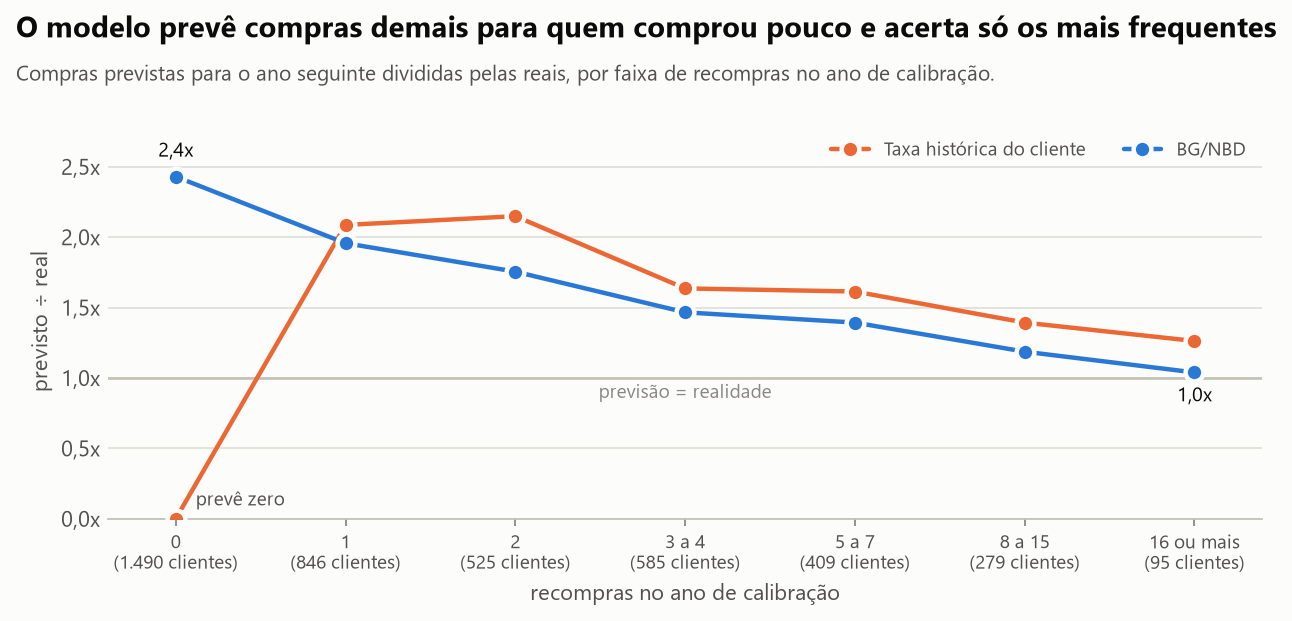

In [7]:
calibracao = analise.calibracao_por_frequencia(base, previsoes)
display(calibracao)
mostrar(graficos.calibracao_por_frequencia(calibracao))

E mês a mês: o modelo prevê um ano plano. A realidade tem vale em janeiro e fevereiro e pico em novembro, e fica
abaixo do previsto em onze dos doze meses.

,real,modelo,taxa_historica,modelo_sobre_real
mes,,,,
2010-12,1120,"1,563.963","1,498.450",1.396
2011-01,848,"1,562.097","1,498.450",1.842
2011-02,778,"1,409.346","1,353.439",1.811
2011-03,967,"1,558.622","1,498.450",1.612
2011-04,840,"1,506.642","1,450.113",1.794
2011-05,1066,"1,555.128","1,498.450",1.459
2011-06,963,"1,503.306","1,450.113",1.561
2011-07,896,"1,551.727","1,498.450",1.732
2011-08,894,"1,550.032","1,498.450",1.734


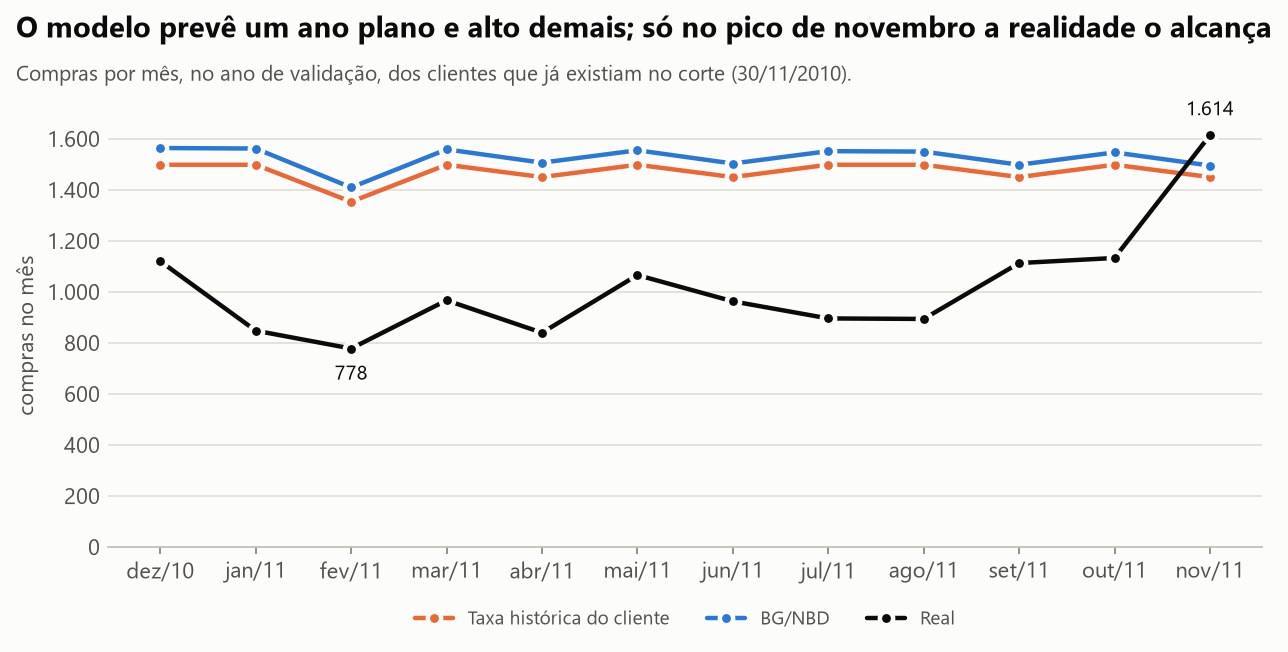

In [8]:
mensal = analise.acompanhamento_mensal(base, bg, compras_liquidas)
display(mensal)
mostrar(graficos.sazonalidade(mensal))

## 4. Onde está a receita do ano seguinte

Para o negócio, a pergunta prática é de ordenação: se eu só puder cuidar de perto de 10% ou 20% dos clientes, quais?
Cada método gera uma lista; mede-se quanto da receita do ano seguinte está no topo dela. A coluna `menos_modelo`
compara cada método com o modelo nas mesmas reamostras.

,top10,top10_inferior,top10_superior,top10_menos_modelo,top10_menos_modelo_inferior,top10_menos_modelo_superior,top20,top20_inferior,top20_superior,top20_menos_modelo,top20_menos_modelo_inferior,top20_menos_modelo_superior,correlacao_de_postos
BG/NBD + Gamma-Gamma,0.612,0.550,0.664,0.000,0.000,0.000,0.741,0.698,0.777,0.000,0.000,0.000,0.603
Taxa histórica x ticket do cliente,0.600,0.536,0.653,-0.013,-0.022,-0.006,0.738,0.693,0.774,-0.003,-0.009,0.002,0.601
Gasto histórico total,0.608,0.544,0.659,-0.005,-0.017,0.004,0.738,0.695,0.775,-0.003,-0.014,0.007,0.620
RFM (M = gasto total),0.477,0.416,0.535,-0.135,-0.204,-0.079,0.671,0.608,0.724,-0.070,-0.136,-0.029,0.620
RFM (M = ticket médio),0.529,0.457,0.592,-0.083,-0.150,-0.042,0.691,0.646,0.733,-0.050,-0.076,-0.030,0.621
Média da base (não ordena),0.100,0.100,0.100,-0.512,-0.564,-0.450,0.200,0.200,0.200,-0.541,-0.577,-0.498,0.000
Ordem perfeita (teto),0.688,0.638,0.729,0.075,0.060,0.093,0.832,0.804,0.855,0.091,0.075,0.109,1.000


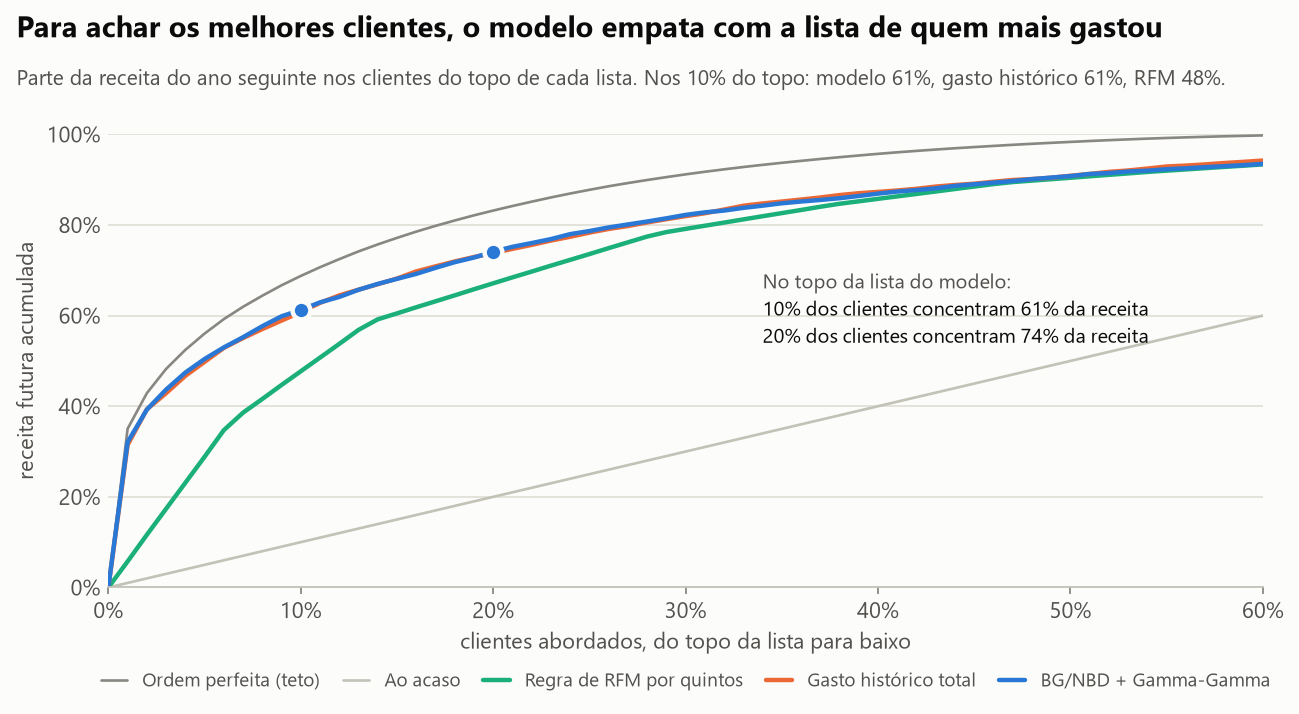

In [9]:
captura = analise.captura_de_receita(base, previsoes, indices)
display(captura)
mostrar(graficos.captura_de_receita(analise.curvas_de_captura(base, previsoes, pontos=101), captura))

**Empate.** A lista do modelo e a lista de quem mais gastou até hoje capturam praticamente a mesma receita, e o
intervalo da diferença inclui o zero. A regra de RFM por quintos perde: ao somar três notas de 1 a 5, ela achata
justamente a diferença entre o cliente grande e o enorme, que é onde a receita está. O teto (ordem perfeita) mostra
que não sobra muito para ganhar.

## 5. O valor por compra (Gamma-Gamma)

A hipótese do modelo é que o valor por compra não depende da frequência. Conferindo:

In [10]:
independencia = analise.independencia_frequencia_valor(base)
display(pd.Series({k: v for k, v in independencia.items() if k != "ticket_por_faixa_de_compras"}, name="valor").to_frame())
independencia["ticket_por_faixa_de_compras"]

,valor
correlacao_de_postos,0.220
correlacao_de_postos_ic,"[0.191164, 0.24854]"
correlacao_linear,0.117
correlacao_linear_ic,"[0.065197, 0.180622]"


,clientes,ticket_mediano,ticket_medio
compras,,,
1,1490,249.190,370.567
2,846,286.183,379.597
3 a 5,1110,318.429,430.658
6 a 10,539,327.130,409.138
11 ou mais,244,425.734,641.116


A hipótese não vale exatamente: quem compra mais vezes gasta um pouco mais por compra (correlação fraca, mas com
intervalo longe do zero). Multiplicar compras esperadas por ticket esperado, como se fossem independentes, subestima
um pouco os clientes grandes.

E o modelo prevê melhor o ticket futuro do que a média crua do cliente?

In [11]:
analise.erro_no_ticket(base, previsoes)

,clientes,erro_absoluto_medio,erro_absoluto_mediano,eam_com_1_compra_no_historico,eam_com_2_ou_mais,eam_menos_media_do_cliente,diferenca_inferior,diferenca_superior
Gamma-Gamma,"2,698.000",159.539,98.092,180.369,153.746,-8.789,-15.355,-3.036
Média do próprio cliente,"2,698.000",168.328,82.437,204.690,158.216,0.000,0.000,0.000
Média da base,"2,698.000",246.890,177.147,232.744,250.824,78.563,65.180,92.492


Na média, sim, e o ganho está onde se esperava: em quem só tinha uma compra no histórico. Na mediana, a média crua
do cliente erra menos: puxar para a média da base ajuda nos casos extremos e atrapalha um pouco nos comuns.

## 6. Quanto vale um cliente novo

A previsão do modelo para quem acabou de fazer a primeira compra: recompras esperadas em *t* semanas vezes o ticket
médio da base. A incerteza dos parâmetros vem de reajustar os dois modelos em 200 reamostras de clientes.

A conferência usa os **clientes novos do ano de validação**: gente cuja primeira compra na base aconteceu depois do
corte, quando já havia um ano de histórico sem eles.

In [12]:
reajustes = analise.reajustes_por_bootstrap(base, bg, gama)
novo = analise.valor_do_cliente_novo(compras, cancelamentos, base, bg, gama, reajustes)
novo["tabela"].T

,13 semanas,26 semanas,39 semanas
clientes_novos_acompanhados,"1,022.000",716.000,344.000
real_recompras,0.762,1.327,1.657
real_recompras_inferior,0.681,1.166,1.363
real_recompras_superior,0.849,1.499,1.965
real_receita,291.230,473.465,710.924
real_receita_inferior,218.878,383.236,493.034
real_receita_superior,408.974,576.351,979.928
real_parcela_sem_recompra,0.594,0.494,0.462
real_receita_mediana,0.000,48.575,120.400
real_valor_da_primeira_compra,372.286,364.433,356.791


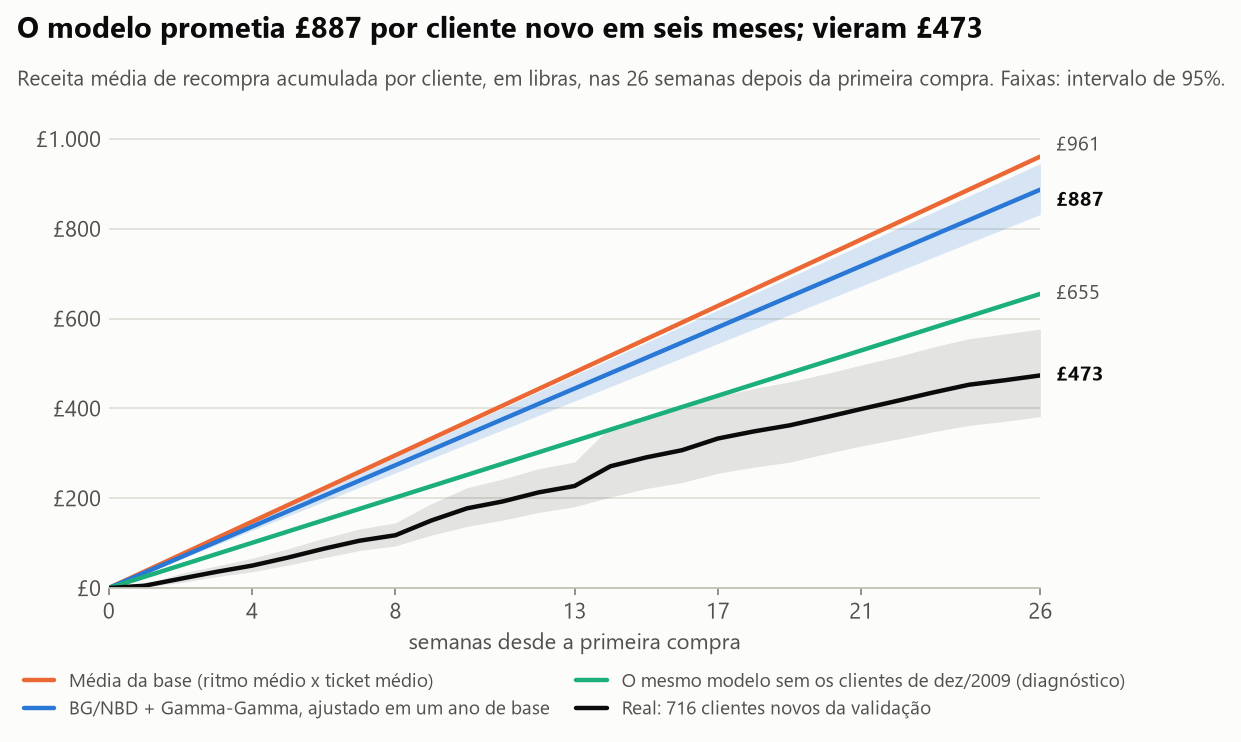

In [13]:
mostrar(graficos.valor_do_cliente_novo(novo["curvas"], novo["tabela"].loc[f"{analise.HORIZONTE_PRINCIPAL} semanas"]))

**O modelo promete quase o dobro do que os clientes novos entregaram**, e a faixa de incerteza dele é estreita:
ela mede o erro de amostragem dos parâmetros, não o erro de o modelo estar descrevendo a população errada.

De onde vem o erro? A base começa em dezembro de 2009 e não diz quem já era cliente antes. Quem aparece no primeiro
mês é, em boa parte, cliente antigo, que compra muito mais. As linhas de diagnóstico da tabela refazem as contas sem
esse primeiro mês: a previsão cai bastante, mas continua acima do real. (Essa variante foi tentada depois de ver o
erro; ela explica a causa, não é uma validação limpa.)

O valor de *um* cliente também varia muito mais do que a média sugere:

In [14]:
display(novo["distribuicao"])
pd.Series({k: v for k, v in novo.items() if k not in ("tabela", "curvas", "distribuicao", "diagnostico_bgnbd")}, name="valor").to_frame()

,parcela_sem_recompra,mediana,percentil_75,percentil_90,percentil_99,media
modelo (simulado),0.327,364.864,"1,105.096","2,317.133","7,246.468",888.151
real (novos da validação),0.494,48.575,471.350,"1,138.460","5,266.949",473.465


,valor
fim_do_primeiro_mes,2009-12-31
clientes_do_primeiro_mes,951
novos_por_mes_depois_do_primeiro,298.000
novos_por_mes_na_validacao,132.167


## 7. Quando considerar que o cliente foi embora

Aqui não há contrato nem cancelamento: o abandono nunca é observado, só o silêncio. Duas ferramentas:

**Kaplan-Meier** para o tempo até a segunda compra. Quem ainda não voltou quando os dados acabam entra como
censurado (sabe-se só que o tempo dele é maior do que o observado).

,clientes,voltaram,semanas_medianas_ate_voltar,voltou_em_13,voltou_em_13_inferior,voltou_em_13_superior,voltou_em_26,voltou_em_26_inferior,voltou_em_26_superior
Primeira compra em dez/2009 (visto no corte),951.000,848.000,8.857,0.601,0.570,0.633,0.781,0.755,0.807
Primeira compra de jan a nov/2010 (visto no corte),"3,278.000","1,891.000",16.000,0.448,0.430,0.467,0.653,0.634,0.672
Clientes novos da validação (dez/2010 em diante),"1,613.000",840.000,16.286,0.448,0.422,0.475,0.587,0.559,0.616


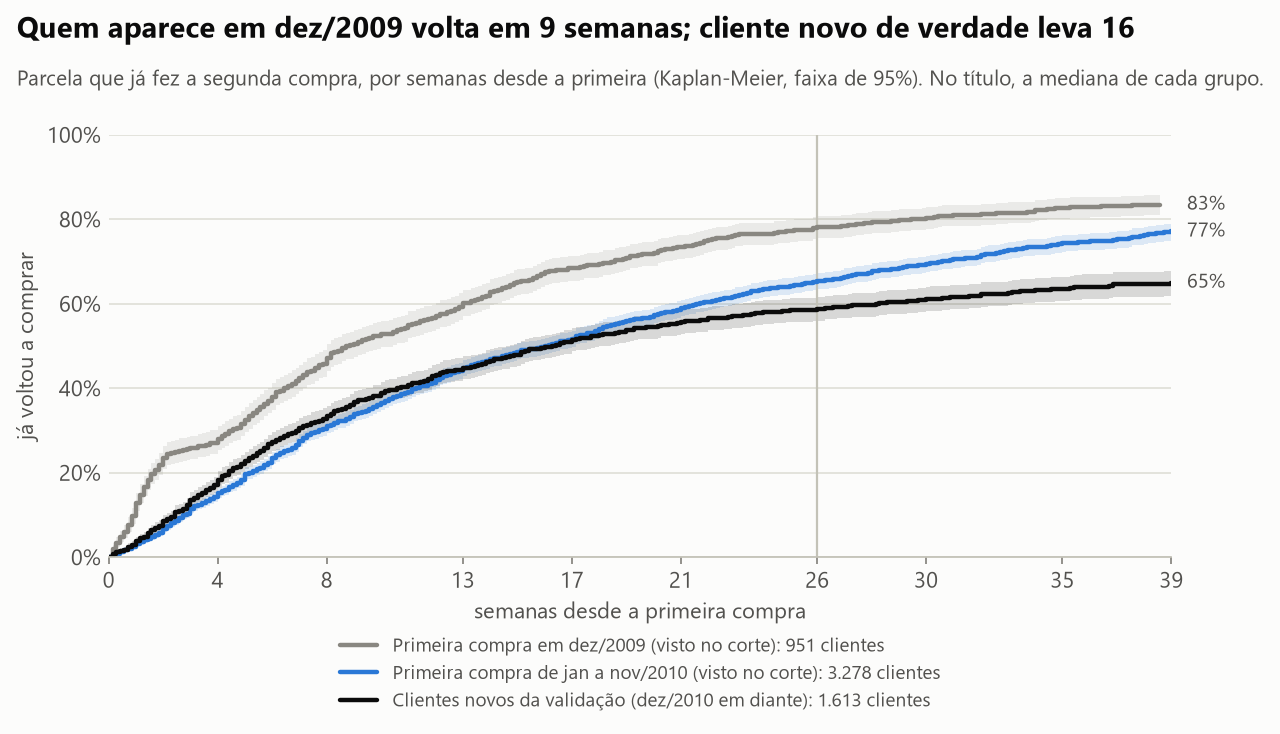

In [15]:
sobrevivencia = analise.curvas_de_sobrevivencia(compras, cancelamentos)
display(sobrevivencia["tabela"])
mostrar(graficos.tempo_ate_a_recompra(sobrevivencia["curvas"], sobrevivencia["tabela"]))

A curva de quem aparece em dezembro de 2009 confirma o diagnóstico da seção 6: esse grupo volta rápido demais
para ser de clientes novos.

A chance de voltar nas 26 semanas seguintes, dado que o cliente já está calado há algum tempo, sai da própria curva:
1 − S(silêncio + 26) / S(silêncio).

In [16]:
pd.DataFrame({grupo: {k: v["chance_de_voltar_em_26_semanas"] for k, v in valores.items()} for grupo, valores in sobrevivencia["chance_de_voltar"].items()})

,Primeira compra em dez/2009 (visto no corte),Primeira compra de jan a nov/2010 (visto no corte),Clientes novos da validação (dez/2010 em diante)
calado há 0 semanas,0.781,0.653,0.587
calado há 4 semanas,0.727,0.640,0.524
calado há 13 semanas,0.586,0.585,0.366


**A conferência direta.** No corte, cada cliente estava calado há um certo tempo. Quantos voltaram nas 26 e nas
52 semanas seguintes? Ao lado, a probabilidade de compra em 26 semanas que o BG/NBD dava a cada grupo.

,grupo,semanas_calado,clientes,modelo_26,voltou_26,voltou_26_inferior,voltou_26_superior,voltou_52,voltou_52_inferior,voltou_52_superior
0,Comprou duas vezes ou mais,até 4,1303,0.858,0.724,0.699,0.747,0.868,0.849,0.885
1,Comprou duas vezes ou mais,5 a 13,885,0.758,0.599,0.566,0.631,0.765,0.736,0.792
2,Comprou duas vezes ou mais,14 a 26,346,0.679,0.408,0.357,0.460,0.601,0.549,0.651
3,Comprou duas vezes ou mais,27 a 39,165,0.580,0.364,0.294,0.439,0.497,0.422,0.572
4,Comprou duas vezes ou mais,40 ou mais,40,0.502,0.300,0.181,0.454,0.325,0.201,0.480
5,Comprou uma vez,até 4,282,0.637,0.312,0.261,0.368,0.496,0.439,0.554
6,Comprou uma vez,5 a 13,407,0.551,0.275,0.234,0.321,0.489,0.441,0.537
7,Comprou uma vez,14 a 26,251,0.428,0.211,0.165,0.266,0.351,0.294,0.411
8,Comprou uma vez,27 a 39,303,0.348,0.234,0.190,0.285,0.337,0.286,0.392
9,Comprou uma vez,40 ou mais,247,0.291,0.117,0.083,0.164,0.235,0.186,0.291


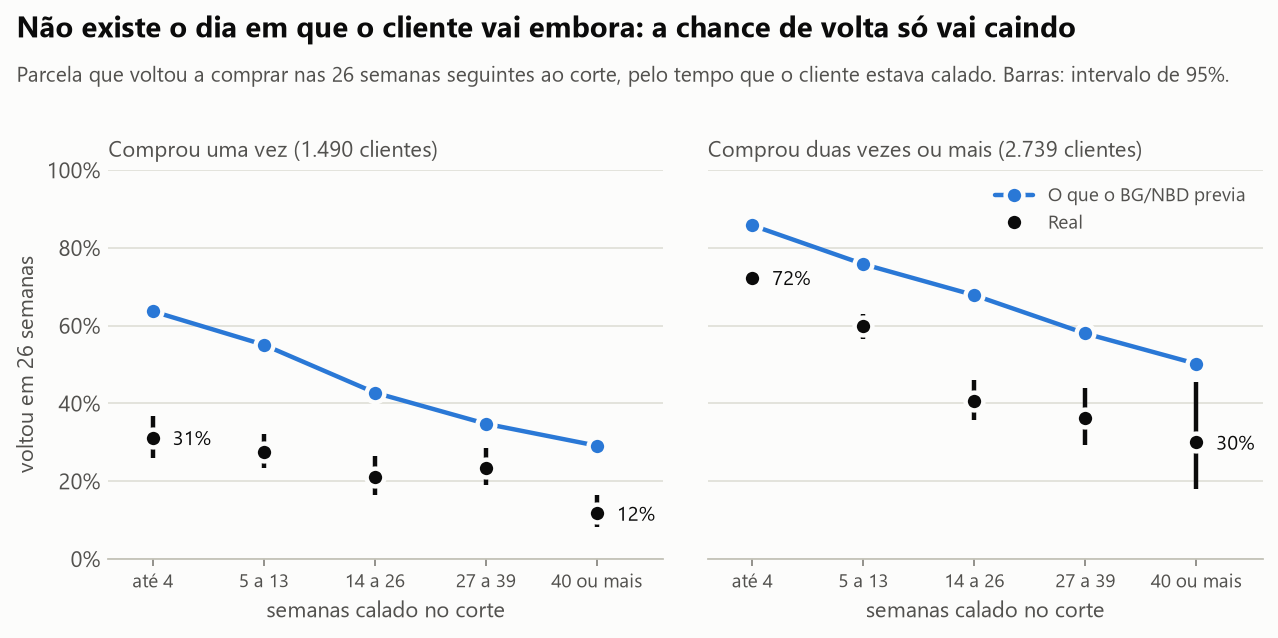

In [17]:
silencio = analise.retorno_por_silencio(base, bg, compras_liquidas)
display(silencio)
mostrar(graficos.retorno_por_silencio(silencio))

Não aparece um ponto de corte: a chance de volta cai aos poucos com o silêncio, e mesmo entre quem comprou uma vez
e estava calado havia mais de nove meses, cerca de um em cada quatro voltou dentro de um ano. O que muda muito é o
ponto de partida: quem só comprou uma vez já começa com chance baixa. O BG/NBD, que não enxergou abandono, promete
volta demais em todas as faixas.

## 8. O resultado depende do corte?

Refazendo tudo com outros cortes. A coluna do meio é a análise principal.

In [18]:
analise.sensibilidade_ao_corte(compras, cancelamentos).T

,2010-08-31 → 2011-08-31,2010-11-30 → 2011-11-30,2010-12-31 → 2011-11-30,2011-02-28 → 2011-11-30,2011-05-31 → 2011-11-30
semanas_de_calibracao,39.000,52.000,56.000,65.000,78.000
semanas_de_validacao,52.000,52.000,48.000,39.000,26.000
clientes,"3,294.000","4,229.000","4,303.000","4,502.000","4,899.000"
abandono_medio_por_recompra,0.003,0.002,0.003,0.021,0.045
probabilidade_vivo_media,0.997,0.996,0.991,0.957,0.915
vies_modelo,0.185,0.496,0.415,0.179,0.005
vies_modelo_inferior,0.131,0.443,0.361,0.138,-0.023
vies_modelo_superior,0.229,0.552,0.474,0.220,0.039
vies_taxa_historica,0.111,0.442,0.375,0.191,0.072
eam_modelo,2.392,2.499,2.098,1.529,1.026


- **Ordenação: estável.** Em todos os cortes o modelo fica de zero a dois pontos acima do gasto histórico, e sempre
  acima da regra de RFM.
- **Volume: instável.** O excesso de compras previstas vai de quase zero a 50% conforme o corte. É pior quando a
  calibração termina no pico de fim de ano (tudo parece vivo e acelerando) e some quando o modelo já viu o silêncio de
  janeiro e fevereiro do segundo ano: só aí o abandono médio estimado sai do zero.

## Conclusão

1. Com um ano de histórico, o modelo de valor do cliente **ordena bem, mas não melhor do que "quem mais gastou"**.
2. **Como previsão de volume e de valor do cliente novo, ele erra para cima**, e a regra simples erra junto: o problema
   está nos dados (não se sabe quem é novo; um ano sazonal esconde o abandono), não na conta.
3. **"Foi embora" não tem data.** O que há é uma chance de volta que cai com o silêncio e que depende, antes de tudo,
   de o cliente já ter voltado alguma vez.